# NYC Public School SAT Results: Pandas + SQL + Statistical Testing

**Questions**
1. Which schools are best for math (average math score of at least 640, i.e. 80% of the 800 maximum)?
2. Who are the top 10 schools by total SAT score?
3. Which NYC borough has the highest standard deviation of total SAT scores?

**Going beyond the brief:** the same answers are reproduced in SQL (DuckDB: CTE, JOIN, window functions) and cross-checked against Pandas. I then test whether boroughs differ in *level* and in *spread*, and how much to trust the "largest standard deviation" answer given very different sample sizes.

**Data:** `schools.csv`, one row per NYC public high school (375 rows): borough, building code, average SAT math / reading / writing score, and `percent_tested`.

In [1]:
from itertools import combinations
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 70)
Path("images").mkdir(exist_ok=True)
RNG = np.random.default_rng(42)  # fixed seed so the bootstrap is reproducible

## 1. Load and check the data

In [2]:
schools = pd.read_csv("schools.csv")
print(f"Rows: {schools.shape[0]}, Columns: {schools.shape[1]}")
schools.head()

Rows: 375, Columns: 7


,school_name,borough,building_code,average_math,average_reading,average_writing,percent_tested
0,"New Explorations into Science, Technology and Math High School",Manhattan,M022,657,601,601,NaN
1,Essex Street Academy,Manhattan,M445,395,411,387,78.9
2,Lower Manhattan Arts Academy,Manhattan,M445,418,428,415,65.1
3,High School for Dual Language and Asian Studies,Manhattan,M445,613,453,463,95.9
4,Henry Street School for International Studies,Manhattan,M056,410,406,381,59.7


In [3]:
schools.info()
print("\nMissing values per column:\n", schools.isna().sum(), sep="")
print("\nDuplicate rows:", schools.duplicated().sum())
print("Duplicate school names:", schools["school_name"].duplicated().sum())

score_cols = ["average_math", "average_reading", "average_writing"]
assert schools[score_cols].min().min() >= 200 and schools[score_cols].max().max() <= 800, \
    "A section score is outside the valid 200-800 SAT range"
print("\nAll section scores are inside the valid 200-800 range.")

print("\nSchools with missing percent_tested, by borough:")
schools.loc[schools["percent_tested"].isna(), "borough"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   school_name      375 non-null    str    
 1   borough          375 non-null    str    
 2   building_code    375 non-null    str    
 3   average_math     375 non-null    int64  
 4   average_reading  375 non-null    int64  
 5   average_writing  375 non-null    int64  
 6   percent_tested   355 non-null    float64
dtypes: float64(1), int64(3), str(3)
memory usage: 20.6 KB

Missing values per column:
school_name         0
borough             0
building_code       0
average_math        0
average_reading     0
average_writing     0
percent_tested     20
dtype: int64

Duplicate rows: 0
Duplicate school names: 0

All section scores are inside the valid 200-800 range.

Schools with missing percent_tested, by borough:


borough
Manhattan        5
Bronx            5
Brooklyn         5
Queens           4
Staten Island    1
Name: count, dtype: int64

**Data-quality notes.** No duplicates, and all section scores are within the valid 200-800 range. Only `percent_tested` has gaps (20 schools). I keep those schools for every score-based question and drop them only where `percent_tested` is used.

## 2. The three questions in Pandas

In [4]:
# Q1. Best schools for math: at least 80% of the 800-point maximum
MATH_THRESHOLD = 0.8 * 800  # = 640

best_math_schools = (
    schools.loc[schools["average_math"] >= MATH_THRESHOLD, ["school_name", "average_math"]]
    .sort_values(["average_math", "school_name"], ascending=[False, True])
    .reset_index(drop=True)
)
print(f"{len(best_math_schools)} schools scored at least {MATH_THRESHOLD:.0f} in math")
best_math_schools

10 schools scored at least 640 in math


,school_name,average_math
0,Stuyvesant High School,754
1,Bronx High School of Science,714
2,Staten Island Technical High School,711
3,Queens High School for the Sciences at York College,701
4,"High School for Mathematics, Science, and Engineering at City College",683
5,Brooklyn Technical High School,682
6,Townsend Harris High School,680
7,High School of American Studies at Lehman College,669
8,"New Explorations into Science, Technology and Math High School",657
9,Eleanor Roosevelt High School,641


In [5]:
# Q2. Top 10 schools by total SAT (school_name breaks ties so results are deterministic)
schools["total_SAT"] = schools[score_cols].sum(axis=1)

top_10_schools = (
    schools[["school_name", "total_SAT"]]
    .sort_values(["total_SAT", "school_name"], ascending=[False, True])
    .head(10)
    .reset_index(drop=True)
)
top_10_schools

,school_name,total_SAT
0,Stuyvesant High School,2144
1,Bronx High School of Science,2041
2,Staten Island Technical High School,2041
3,High School of American Studies at Lehman College,2013
4,Townsend Harris High School,1981
5,Queens High School for the Sciences at York College,1947
6,Bard High School Early College,1914
7,Brooklyn Technical High School,1896
8,Eleanor Roosevelt High School,1889
9,"High School for Mathematics, Science, and Engineering at City College",1889


In [6]:
# Q3. Which borough has the largest standard deviation of total SAT?
boroughs = (
    schools.groupby("borough")["total_SAT"]
    .agg(num_schools="count", average_SAT="mean", std_SAT="std", median_SAT="median")
    .round(2)
    .sort_values("std_SAT", ascending=False)
)
largest_std_dev = boroughs.head(1).reset_index()

print("Borough with the largest standard deviation:")
display(largest_std_dev)
boroughs

Borough with the largest standard deviation:


,borough,num_schools,average_SAT,std_SAT,median_SAT
0,Manhattan,89,1340.13,230.29,1284.0


,num_schools,average_SAT,std_SAT,median_SAT
borough,,,,
Manhattan,89,1340.13,230.29,1284.0
Staten Island,10,1439.00,222.30,1382.0
Queens,69,1345.48,195.25,1290.0
Brooklyn,109,1230.26,154.87,1186.0
Bronx,98,1202.72,150.39,1190.0


## 3. The same answers in SQL (DuckDB)

SQL is the standard way analysts query company databases, so I reproduced each answer with SQL and then **asserted that the results are identical to Pandas**. `STDDEV_SAMP` is used because Pandas' `.std()` is the sample standard deviation.

In [7]:
con = duckdb.connect()
con.register("schools", schools)

sql_best_math = con.sql("""
    SELECT school_name, average_math
    FROM schools
    WHERE average_math >= 640
    ORDER BY average_math DESC, school_name
""").df()

sql_top_10 = con.sql("""
    SELECT school_name,
           average_math + average_reading + average_writing AS total_SAT
    FROM schools
    ORDER BY total_SAT DESC, school_name
    LIMIT 10
""").df()

sql_borough_std = con.sql("""
    WITH t AS (
        SELECT borough,
               average_math + average_reading + average_writing AS total_SAT
        FROM schools
    )
    SELECT borough,
           COUNT(*)                         AS num_schools,
           ROUND(AVG(total_SAT), 2)         AS average_SAT,
           ROUND(STDDEV_SAMP(total_SAT), 2) AS std_SAT
    FROM t
    GROUP BY borough
    ORDER BY std_SAT DESC
""").df()

# Cross-check: SQL must reproduce the Pandas results exactly
pd.testing.assert_frame_equal(sql_best_math, best_math_schools, check_dtype=False)
pd.testing.assert_frame_equal(sql_top_10, top_10_schools, check_dtype=False)
pd.testing.assert_frame_equal(
    sql_borough_std,
    boroughs.reset_index()[["borough", "num_schools", "average_SAT", "std_SAT"]],
    check_dtype=False,
)
print("SQL results match Pandas for all three questions.")
sql_borough_std

SQL results match Pandas for all three questions.


,borough,num_schools,average_SAT,std_SAT
0,Manhattan,89,1340.13,230.29
1,Staten Island,10,1439.00,222.30
2,Queens,69,1345.48,195.25
3,Brooklyn,109,1230.26,154.87
4,Bronx,98,1202.72,150.39


### Window function and JOIN queries

In [8]:
# Best school in each borough: RANK() window function
top_per_borough = con.sql("""
    SELECT borough, school_name, total_SAT
    FROM (
        SELECT borough, school_name, total_SAT,
               RANK() OVER (PARTITION BY borough ORDER BY total_SAT DESC) AS rank_in_borough
        FROM schools
    )
    WHERE rank_in_borough = 1
    ORDER BY total_SAT DESC
""").df()
top_per_borough

,borough,school_name,total_SAT
0,Manhattan,Stuyvesant High School,2144
1,Staten Island,Staten Island Technical High School,2041
2,Bronx,Bronx High School of Science,2041
3,Queens,Townsend Harris High School,1981
4,Brooklyn,Brooklyn Technical High School,1896


In [9]:
# Which schools beat their own borough's average by the most? (CTE + JOIN)
above_borough_avg = con.sql("""
    WITH borough_stats AS (
        SELECT borough, AVG(total_SAT) AS borough_avg
        FROM schools
        GROUP BY borough
    )
    SELECT s.school_name,
           s.borough,
           s.total_SAT,
           ROUND(b.borough_avg, 1)                AS borough_avg,
           ROUND(s.total_SAT - b.borough_avg, 1)  AS points_above_avg
    FROM schools AS s
    JOIN borough_stats AS b ON s.borough = b.borough
    ORDER BY points_above_avg DESC, s.school_name
    LIMIT 5
""").df()
above_borough_avg

,school_name,borough,total_SAT,borough_avg,points_above_avg
0,Bronx High School of Science,Bronx,2041,1202.7,838.3
1,High School of American Studies at Lehman College,Bronx,2013,1202.7,810.3
2,Stuyvesant High School,Manhattan,2144,1340.1,803.9
3,Brooklyn Technical High School,Brooklyn,1896,1230.3,665.7
4,Townsend Harris High School,Queens,1981,1345.5,635.5


## 4. Looking deeper: what drives the scores?

In [10]:
# Spearman correlation is robust to the skew in school-level scores
corr = schools[score_cols + ["percent_tested", "total_SAT"]].corr(method="spearman").round(2)
corr

,average_math,average_reading,average_writing,percent_tested,total_SAT
average_math,1.00,0.87,0.88,0.62,0.94
average_reading,0.87,1.00,0.96,0.59,0.98
average_writing,0.88,0.96,1.00,0.60,0.98
percent_tested,0.62,0.59,0.60,1.00,0.61
total_SAT,0.94,0.98,0.98,0.61,1.00


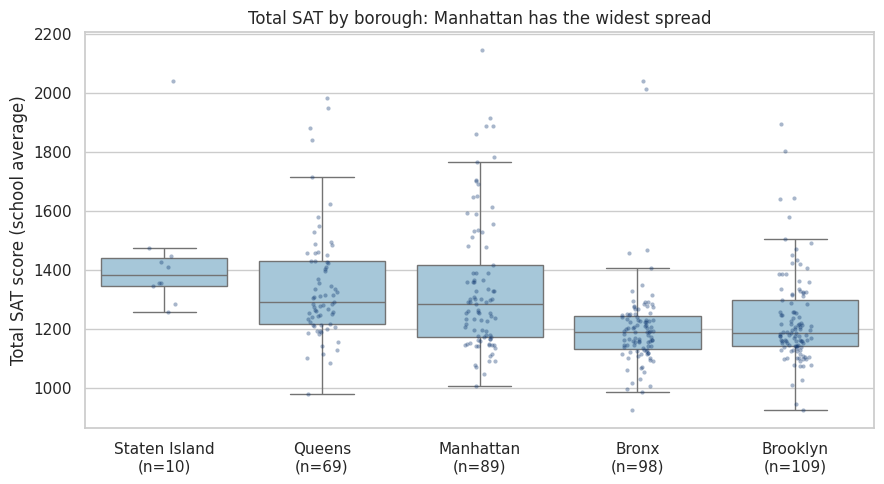

In [11]:
order = boroughs.sort_values("median_SAT", ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=schools, x="borough", y="total_SAT", order=order,
            color="#9ecae1", fliersize=0, ax=ax)
sns.stripplot(data=schools, x="borough", y="total_SAT", order=order,
              color="#08306b", alpha=0.35, size=3, ax=ax)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{b}\n(n={boroughs.loc[b, 'num_schools']})" for b in order])
ax.set_xlabel("")
ax.set_ylabel("Total SAT score (school average)")
ax.set_title("Total SAT by borough: Manhattan has the widest spread")
plt.tight_layout()
fig.savefig("images/sat_by_borough.png", dpi=150)
plt.show()

Spearman correlation, percent_tested vs total_SAT: rho = 0.61, p = 5.1e-37  (n = 355)


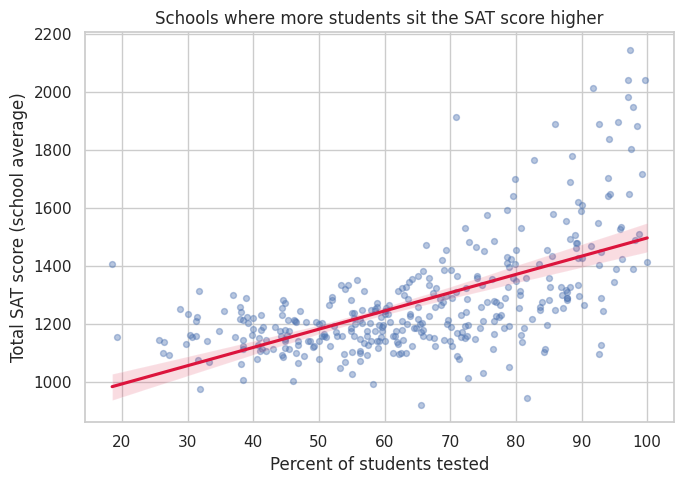

In [12]:
tested = schools.dropna(subset=["percent_tested"])
rho, p = stats.spearmanr(tested["percent_tested"], tested["total_SAT"])
print(f"Spearman correlation, percent_tested vs total_SAT: rho = {rho:.2f}, p = {p:.1e}  (n = {len(tested)})")

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=tested, x="percent_tested", y="total_SAT",
            scatter_kws={"alpha": 0.4, "s": 18}, line_kws={"color": "crimson"}, ax=ax)
ax.set_xlabel("Percent of students tested")
ax.set_ylabel("Total SAT score (school average)")
ax.set_title("Schools where more students sit the SAT score higher")
plt.tight_layout()
fig.savefig("images/tested_vs_sat.png", dpi=150)
plt.show()

## 5. Statistical tests

Two separate questions:
- **Do boroughs differ in typical score?** Scores are not normally distributed (see Shapiro-Wilk below), so I use the **Kruskal-Wallis** test, with epsilon-squared as the effect size.
- **Do boroughs differ in spread?** **Levene's test** (median-centred, robust to non-normality).

In [13]:
groups = {b: g["total_SAT"].to_numpy() for b, g in schools.groupby("borough")}

normality = pd.Series({b: stats.shapiro(v).pvalue for b, v in groups.items()}, name="shapiro_p")
print("Shapiro-Wilk p-values (small = not normal):")
print(normality.map("{:.4f}".format).to_string())

kw = stats.kruskal(*groups.values())
n, k = len(schools), len(groups)
epsilon_sq = (kw.statistic - k + 1) / (n - k)
lev = stats.levene(*groups.values(), center="median")

print(f"\nKruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, epsilon-squared = {epsilon_sq:.2f}")
print(f"Levene (equal spread?): W = {lev.statistic:.2f}, p = {lev.pvalue:.4f}")

Shapiro-Wilk p-values (small = not normal):
Bronx            0.0000
Brooklyn         0.0000
Manhattan        0.0000
Queens           0.0000
Staten Island    0.0003

Kruskal-Wallis: H = 59.7, p = 3.3e-12, epsilon-squared = 0.15
Levene (equal spread?): W = 4.50, p = 0.0015


In [14]:
# Which pairs of boroughs differ? Mann-Whitney U with Bonferroni correction
pairs = list(combinations(groups, 2))
pairwise = pd.DataFrame(
    [{"pair": f"{a} vs {b}", "p_raw": stats.mannwhitneyu(groups[a], groups[b]).pvalue} for a, b in pairs]
)
pairwise["p_bonferroni"] = (pairwise["p_raw"] * len(pairs)).clip(upper=1)
pairwise["significant"] = pairwise["p_bonferroni"] < 0.05
pairwise.assign(
    p_raw=pairwise["p_raw"].map("{:.2e}".format),
    p_bonferroni=pairwise["p_bonferroni"].map("{:.2e}".format),
)

,pair,p_raw,p_bonferroni,significant
0,Bronx vs Brooklyn,3.10e-01,1.00e+00,False
1,Bronx vs Manhattan,1.35e-06,1.35e-05,True
2,Bronx vs Queens,1.10e-09,1.10e-08,True
3,Bronx vs Staten Island,6.01e-06,6.01e-05,True
4,Brooklyn vs Manhattan,2.70e-04,2.70e-03,True
5,Brooklyn vs Queens,9.61e-07,9.61e-06,True
6,Brooklyn vs Staten Island,1.80e-04,1.80e-03,True
7,Manhattan vs Queens,3.25e-01,1.00e+00,False
8,Manhattan vs Staten Island,4.84e-02,4.84e-01,False
9,Queens vs Staten Island,7.56e-02,7.56e-01,False


### How much should we trust "Manhattan has the largest standard deviation"?

Staten Island has only 10 schools, so its standard deviation is very uncertain. I bootstrap a 95% confidence interval for each borough's standard deviation (5,000 resamples).

In [15]:
def bootstrap_std_ci(x, n_boot=5000, alpha=0.05):
    idx = RNG.integers(0, len(x), size=(n_boot, len(x)))
    stds = x[idx].std(axis=1, ddof=1)
    return np.percentile(stds, [100 * alpha / 2, 100 * (1 - alpha / 2)])

ci = pd.DataFrame({b: bootstrap_std_ci(v) for b, v in groups.items()}, index=["ci_low", "ci_high"]).T.round(1)
ci.insert(0, "std_SAT", boroughs["std_SAT"])
ci.insert(0, "num_schools", boroughs["num_schools"])
ci.sort_values("std_SAT", ascending=False)

,num_schools,std_SAT,ci_low,ci_high
Manhattan,89,230.29,184.9,269.9
Staten Island,10,222.30,48.7,335.8
Queens,69,195.25,142.7,238.4
Brooklyn,109,154.87,118.7,188.4
Bronx,98,150.39,84.9,209.7


## 6. Key findings

*(Numbers below come from this run of the notebook on the 375-school dataset.)*

**Answers to the three questions**
1. **Best for math:** 10 schools average at least 640. Stuyvesant High School is first (754), then Bronx High School of Science (714) and Staten Island Technical High School (711).
2. **Top 10 by total SAT:** Stuyvesant leads at 2,144, well ahead of Bronx Science and Staten Island Technical (both 2,041).
3. **Largest spread:** Manhattan has the highest standard deviation (230.29, n = 89).

**What the extra analysis adds**
- **Boroughs differ in typical score** (Kruskal-Wallis H = 59.7, p = 3.3e-12, epsilon-squared = 0.15, a medium-to-large effect). After Bonferroni correction, Manhattan, Queens and Staten Island form a higher-scoring group and Bronx and Brooklyn a lower one. Differences *within* those groups are not significant.
- **Spread also differs by borough** (Levene p = 0.0015). Manhattan's interquartile range is the widest because its schools range from selective specialized schools to very low-scoring ones.
- **Caution on "largest standard deviation":** Staten Island is a close second (222.30) but has only 10 schools. Its bootstrap 95% interval (48.7 to 335.8) fully contains Manhattan's (184.9 to 269.9), so the data cannot confirm that Manhattan's spread is truly larger than Staten Island's.
- **Participation matters:** schools where a higher share of students sit the SAT score higher (Spearman rho = 0.61, n = 355). This is an association only. Selective schools may simply have higher participation.

**Limitations**
- Scores are school averages, not student-level data, so the results describe schools, not individual students.
- 20 schools have no `percent_tested` value and were excluded only from the participation analysis.
- Staten Island's small sample (10 schools) makes its statistics unstable.
- The pairwise tests compare score distributions, not causes. Differences between boroughs reflect many unmeasured factors such as admissions policy and school type.